<a href="https://colab.research.google.com/github/FhmiKh19/Probabilitas-Statistika/blob/main/Visualisasi_ProbStat_Kelompokk4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Persiapan pustaka dan gaya grafik

In [1]:
import math, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

os.makedirs("fig", exist_ok=True)

# Warna: tiga warna pertama palet referensi (aman untuk buta warna)
C  = {64: "#2a78d6", 65: "#eb6834", 302: "#1baf7a"}             # per sel
CB = {"811 MHz": "#2a78d6", "2630 MHz": "#1baf7a"}              # per frekuensi
SEQ = ["#0d3d7a", "#2a78d6", "#8fb8ec", "#d9e6f7"]              # Sangat baik -> Buruk
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "figure.dpi": 110})
PCIS = [64, 65, 302]
LBL = {64: "PCI 64 (811 MHz)", 65: "PCI 65 (811 MHz)", 302: "PCI 302 (2630 MHz)"}

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 2. Memuat data
Di Colab akan muncul tombol unggah bila berkas belum ada.

In [ ]:
FILE = "cellular_dataset_500_beragam.xlsx"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()          # pilih cellular_dataset_500_beragam.xlsx
    except ImportError:
        raise FileNotFoundError(f"Letakkan {FILE} di folder yang sama dengan notebook.")

d = pd.read_excel(FILE, sheet_name="Data")
d["Band"] = np.where(d.PCI_Tower == 302, "2630 MHz", "811 MHz")   # PCI 302 = 2630 MHz, PCI 64/65 = 811 MHz
print(d.shape)
d.head()

(500, 13)


,No,Longitude,Latitude,Speed,Distance_to_Tower,Offset_Lon_deg,Offset_Lat_deg,PCI_Tower,RSRP_dBm,RSRQ_dB,SINR_dB,Power_dBm,Band
0,1,12.520112,55.780073,21.51,0.5531,-0.004597,-0.003369,64,-75.44,-13.36,16.18,-55.42,811 MHz
1,116,12.520146,55.779717,13.75,0.5891,-0.004953,-0.003335,64,-69.60,-12.92,22.92,-49.37,811 MHz
2,232,12.519870,55.779310,12.92,0.6376,-0.005360,-0.003611,64,-67.96,-13.01,20.07,-48.11,811 MHz
3,347,12.520079,55.779579,17.39,0.6050,-0.005091,-0.003402,64,-69.60,-13.04,19.95,-49.04,811 MHz
4,463,12.520339,55.779988,4.83,0.5566,-0.004682,-0.003142,64,-73.17,-13.04,18.81,-52.67,811 MHz


## 3. Variabel bantu untuk grafik
- **Lokasi menara** dihitung dari koordinat dikurangi selisih posisi. Catatan: `Offset_Lon_deg` berisi selisih **lintang** dan `Offset_Lat_deg` berisi selisih **bujur** (keterangan di kamus data asli tertukar).
- **Kategori sinyal 4G** (Tabel 2.2): RSRP ≥ −80 Sangat baik, −90 sampai < −80 Baik, −100 sampai < −90 Cukup, < −100 Buruk. RSRQ ≥ −10, −15 sampai < −10, −20 sampai < −15, < −20.
- **Kelompok jarak dan kecepatan** dibagi tiga sama besar (tertil).

In [ ]:
tower_lat = (d.Latitude - d.Offset_Lon_deg).mean()
tower_lon = (d.Longitude - d.Offset_Lat_deg).mean()

def cat_rsrp(x): return "Sangat baik" if x >= -80 else "Baik" if x >= -90 else "Cukup" if x >= -100 else "Buruk"
def cat_rsrq(x): return "Sangat baik" if x >= -10 else "Baik" if x >= -15 else "Cukup" if x >= -20 else "Buruk"
CATS = ["Sangat baik", "Baik", "Cukup", "Buruk"]
d["cat_rsrp"] = d.RSRP_dBm.apply(cat_rsrp)
d["cat_rsrq"] = d.RSRQ_dB.apply(cat_rsrq)

def tertil(col, labels):
    t = d[col].quantile([1/3, 2/3]).values
    return pd.cut(d[col], [-np.inf, t[0], t[1], np.inf], labels=labels), t
d["g_dist"], tdist = tertil("Distance_to_Tower", ["Dekat", "Sedang", "Jauh"])
d["g_speed"], tspd = tertil("Speed", ["Lambat", "Sedang", "Cepat"])
print("Lokasi menara:", round(tower_lat, 5), round(tower_lon, 5))
print("Batas tertil jarak (km):", tdist.round(3), "| kecepatan (km/jam):", tspd.round(2))

Lokasi menara: 55.78467 12.52348
Batas tertil jarak (km): [0.405 0.574] | kecepatan (km/jam): [13.22 21.56]


## Gambar 4.1 Peta titik ukur menurut sel

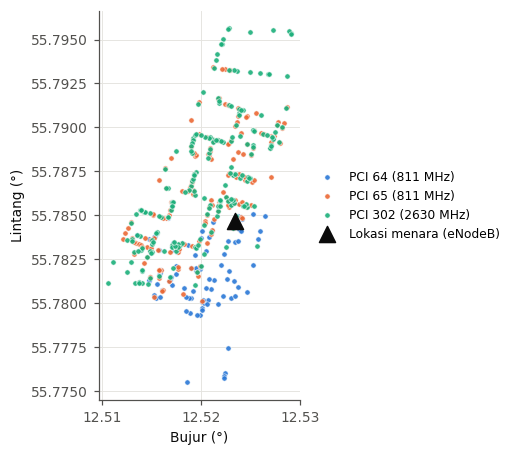

Lokasi menara: 55.78467 12.52348


In [ ]:
tower_lat = (d.Latitude - d.Offset_Lon_deg).mean()
tower_lon = (d.Longitude - d.Offset_Lat_deg).mean()

C = {64: "#2a78d6", 65: "#eb6834", 302: "#1baf7a"}
LBL = {64: "PCI 64 (811 MHz)", 65: "PCI 65 (811 MHz)", 302: "PCI 302 (2630 MHz)"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True})

fig, ax = plt.subplots(figsize=(6.2, 4.6))
for p in [64, 65, 302]:
    s = d[d.PCI_Tower == p]
    ax.scatter(s.Longitude, s.Latitude, s=12, c=C[p], label=LBL[p],
               edgecolors="white", linewidths=0.4, alpha=0.9)
ax.scatter([tower_lon], [tower_lat], marker="^", s=110, c="#0b0b0b",
           label="Lokasi menara (eNodeB)", zorder=5)
ax.set_xlabel("Bujur (°)")
ax.set_ylabel("Lintang (°)")
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_aspect(1 / math.cos(math.radians(55.785)))  # supaya skala bujur-lintang tidak gepeng
ax.ticklabel_format(useOffset=False)

os.makedirs("fig", exist_ok=True)
fig.savefig("fig/g41_peta.png", dpi=300, bbox_inches="tight")
plt.show()
print("Lokasi menara:", round(tower_lat, 5), round(tower_lon, 5))  # harus 55.78467 12.52348

## Gambar 4.2 Histogram jarak ke menara dan kecepatan perangkat

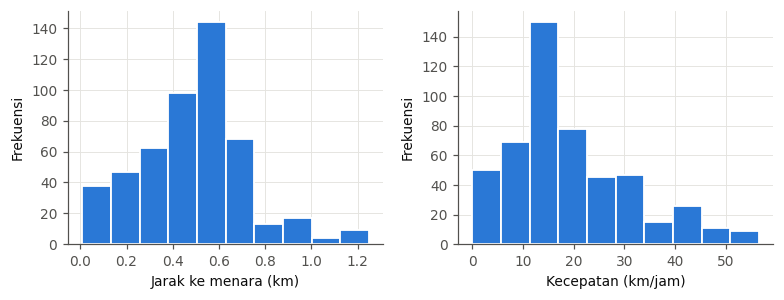

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
axs[0].hist(d.Distance_to_Tower, bins=10, color="#2a78d6", edgecolor="white", linewidth=1.2)
axs[0].set_xlabel("Jarak ke menara (km)"); axs[0].set_ylabel("Frekuensi")
axs[1].hist(d.Speed, bins=10, color="#2a78d6", edgecolor="white", linewidth=1.2)
axs[1].set_xlabel("Kecepatan (km/jam)"); axs[1].set_ylabel("Frekuensi")
fig.tight_layout(); fig.savefig("fig/g42_jarak_kecepatan.png"); plt.show()

## Gambar 4.3 Histogram dan diagram kotak RSRP menurut sel

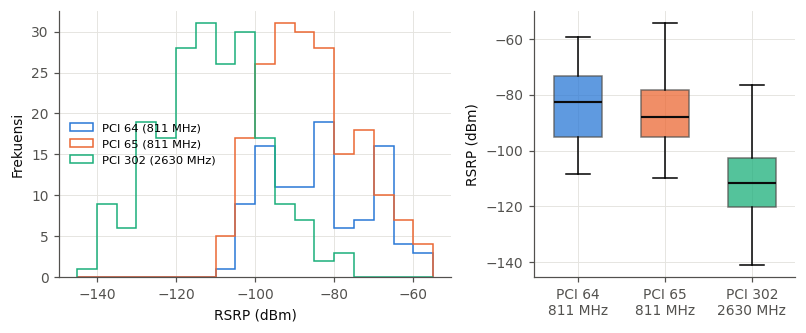

In [ ]:
def box_per_pci(ax, col, ylabel):
    bp = ax.boxplot([d.loc[d.PCI_Tower == p, col] for p in PCIS], patch_artist=True, widths=0.55,
                    medianprops=dict(color=INK, lw=1.4), flierprops=dict(marker="o", ms=3, mfc="none", mec=INK2))
    for b, p in zip(bp["boxes"], PCIS): b.set_facecolor(C[p]); b.set_alpha(0.75); b.set_edgecolor(INK2)
    ax.set_xticks([1, 2, 3], ["PCI 64\n811 MHz", "PCI 65\n811 MHz", "PCI 302\n2630 MHz"]); ax.set_ylabel(ylabel)

fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.1), gridspec_kw={"width_ratios": [1.5, 1]})
bins = np.arange(-145, -50, 5)
for p in PCIS:
    axs[0].hist(d.loc[d.PCI_Tower == p, "RSRP_dBm"], bins=bins, histtype="step", lw=2, color=C[p], label=LBL[p])
axs[0].set_xlabel("RSRP (dBm)"); axs[0].set_ylabel("Frekuensi"); axs[0].legend(frameon=False, fontsize=7.5)
box_per_pci(axs[1], "RSRP_dBm", "RSRP (dBm)")
fig.tight_layout(); fig.savefig("fig/g43_rsrp.png"); plt.show()

## Gambar 4.4 Diagram kotak RSRQ dan SINR menurut sel
Garis putus-putus = SINR 0 dB (di bawahnya gangguan lebih besar daripada sinyal).

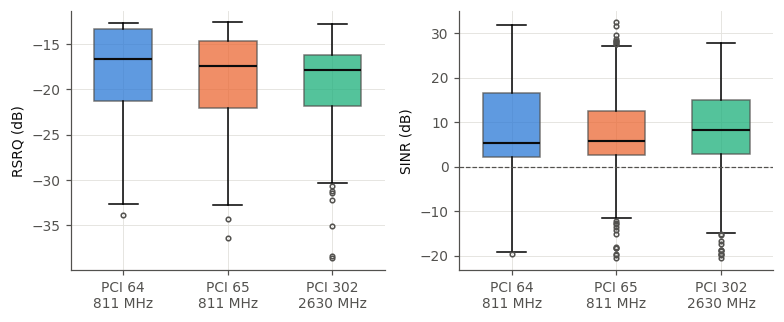

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
box_per_pci(axs[0], "RSRQ_dB", "RSRQ (dB)")
box_per_pci(axs[1], "SINR_dB", "SINR (dB)")
axs[1].axhline(0, color=INK2, lw=0.8, ls="--")
fig.tight_layout(); fig.savefig("fig/g44_rsrq_sinr.png"); plt.show()

## Gambar 4.5 Persentase kategori kualitas sinyal RSRP dan RSRQ menurut sel

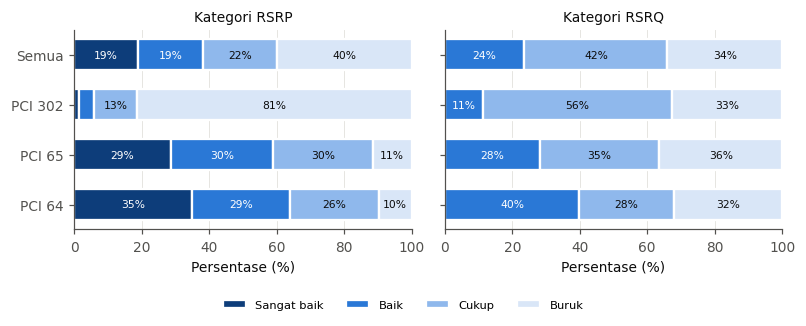

In [ ]:
groups = [("PCI 64", d[d.PCI_Tower == 64]), ("PCI 65", d[d.PCI_Tower == 65]),
          ("PCI 302", d[d.PCI_Tower == 302]), ("Semua", d)]
fig, axs = plt.subplots(1, 2, figsize=(7.4, 2.9), sharey=True)
for ax, v, ttl in [(axs[0], "cat_rsrp", "Kategori RSRP"), (axs[1], "cat_rsrq", "Kategori RSRQ")]:
    pct = np.array([[(g[v] == c).mean() * 100 for c in CATS] for _, g in groups])
    left = np.zeros(len(groups))
    for ci, cn in enumerate(CATS):
        ax.barh(range(len(groups)), pct[:, ci], left=left, color=SEQ[ci], edgecolor="white", linewidth=1.5, label=cn, height=0.62)
        for j, (l, val) in enumerate(zip(left, pct[:, ci])):
            if val >= 8:
                ax.text(l + val/2, j, f"{val:.0f}%", ha="center", va="center", fontsize=7, color="white" if ci < 2 else INK)
        left += pct[:, ci]
    ax.set_yticks(range(len(groups)), [g for g, _ in groups]); ax.invert_yaxis(); ax.set_xlim(0, 100)
    ax.set_xlabel("Persentase (%)"); ax.set_title(ttl, fontsize=9, color=INK); ax.grid(axis="y", visible=False)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, fontsize=7.5, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.08, 1, 1)); fig.savefig("fig/g45_kategori.png"); plt.show()

## Gambar 4.6 Rata-rata RSRP menurut kelompok jarak dan kelompok kecepatan
Dihitung terpisah per frekuensi agar perbedaan frekuensi tidak tercampur.

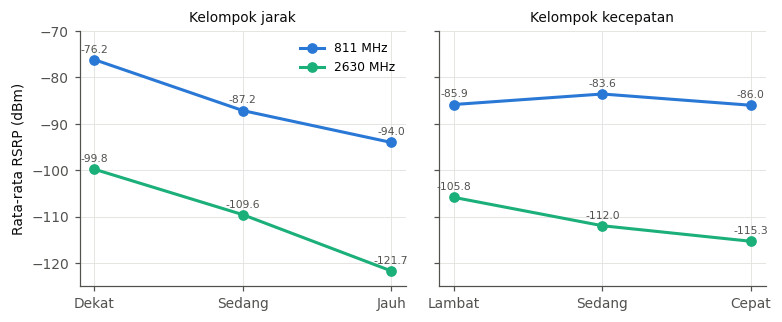

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0), sharey=True)
for ax, gc, labs, ttl in [(axs[0], "g_dist", ["Dekat", "Sedang", "Jauh"], "Kelompok jarak"),
                          (axs[1], "g_speed", ["Lambat", "Sedang", "Cepat"], "Kelompok kecepatan")]:
    for b in ["811 MHz", "2630 MHz"]:
        ys = d[d.Band == b].groupby(gc, observed=True).RSRP_dBm.mean().reindex(labs).values
        ax.plot(labs, ys, "-o", color=CB[b], lw=2, ms=6, label=b)
        for xi, yv in enumerate(ys): ax.text(xi, yv + 1.6, f"{yv:.1f}", ha="center", fontsize=7, color=INK2)
    ax.set_title(ttl, fontsize=9, color=INK); ax.set_ylim(-125, -70)
axs[0].set_ylabel("Rata-rata RSRP (dBm)"); axs[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("fig/g46_kelompok.png"); plt.show()

## Gambar 4.7 Diagram pencar RSRP terhadap jarak ke menara

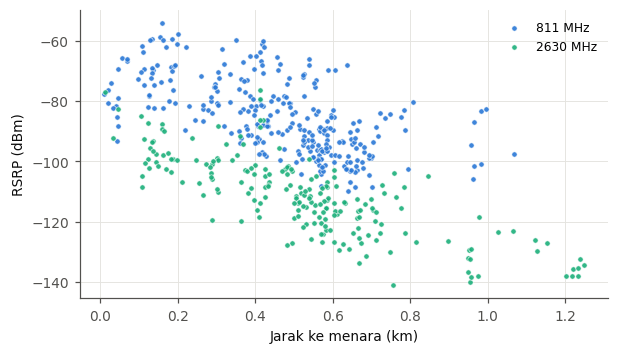

In [ ]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for b in ["811 MHz", "2630 MHz"]:
    s = d[d.Band == b]
    ax.scatter(s.Distance_to_Tower, s.RSRP_dBm, s=12, c=CB[b], label=b, edgecolors="white", linewidths=0.4, alpha=0.9)
ax.set_xlabel("Jarak ke menara (km)"); ax.set_ylabel("RSRP (dBm)"); ax.legend(frameon=False, fontsize=8)
fig.savefig("fig/g47_pencar.png"); plt.show()